**Проверим насколько сбалансированы классы**

In [12]:
import pandas as pd

df = pd.read_csv('brainsize.txt', sep='\t', na_values=['NA'])
men_count = int((df['Gender'] == 'Male').sum())
women_count = int((df['Gender'] == 'Female').sum())

print(f'Count of men: {men_count}')
print(f'Count of women: {women_count}')

Count of men: 20
Count of women: 20


Видим, что в выборке находится равное количество представителей обоих полов. Но при этом видим, что в выборке всего по 20 человек каждого пола. 

То есть такие данные не являются репрезентативными, потому что не могут представлять данные по всему человечеству. Вероятно, это просто студенты одного университета или добровольцы с одного города.

Также такое количество может изменить линию регрессии и создать иллюзию сильной корреляции, так как коэффициент Пирсона измеряет именно линейную связь.

**Scatter-графики**

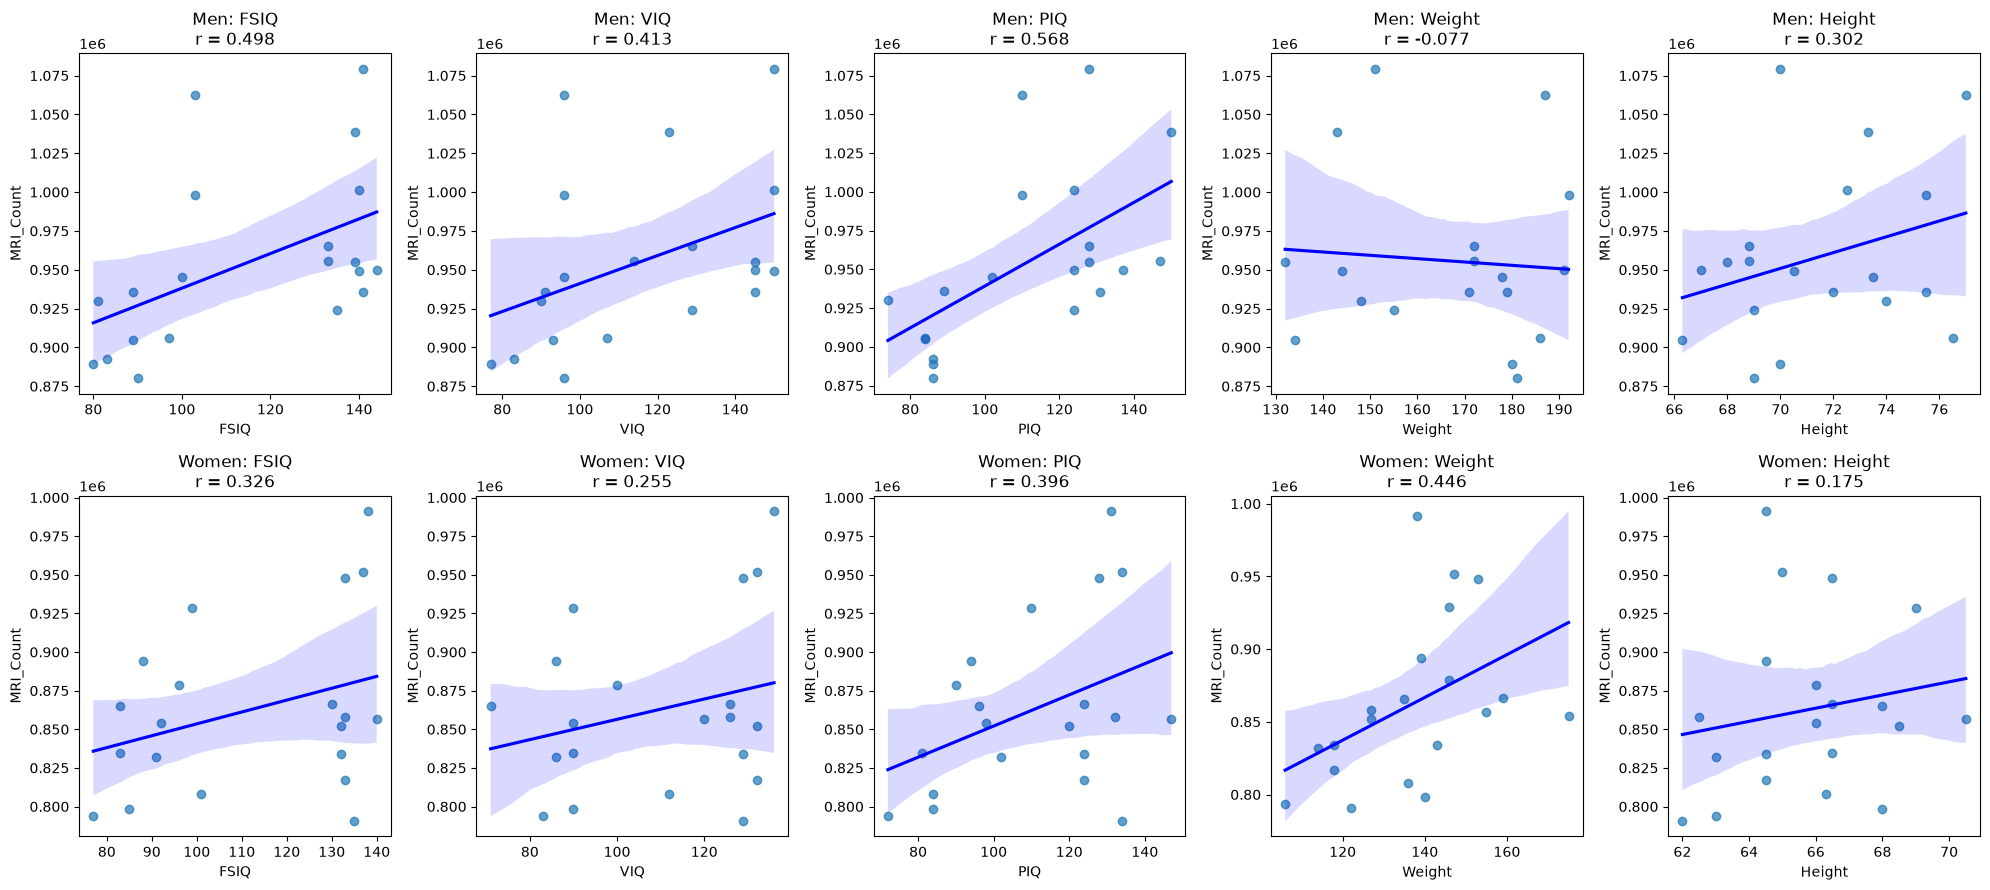

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('brainsize.txt', sep='\t', na_values='NA')

features = ['FSIQ', 'VIQ', 'PIQ', 'Weight', 'Height']

men_df = df[df['Gender'] == 'Male']
women_df = df[df['Gender'] == 'Female']

def plot_brain_correlations(men_df, women_df):
    features = ['FSIQ', 'VIQ', 'PIQ', 'Weight', 'Height']

    fig, axes = plt.subplots(2, 5, figsize=(20, 9))

    groups = [
        (men_df, 'Men'),
        (women_df, 'Women')
    ]

    for row, (group_df, gender) in enumerate(groups):
        for col, feature in enumerate(features):
            ax = axes[row, col]

            sns.regplot(
                data=group_df,
                x=feature,
                y='MRI_Count',
                ax=ax,
                scatter_kws={'alpha': 0.7},
                line_kws={'color': 'blue'}
            )

            correlation = group_df[feature].corr(group_df['MRI_Count'])
            ax.set_title(f'{gender}: {feature}\nr = {correlation:.3f}')
            ax.set_xlabel(feature)
            ax.set_ylabel('MRI_Count')

    plt.tight_layout()
    plt.show()

plot_brain_correlations(men_df, women_df)

На некоторых построенных графиках (например: weight и height) можем видеть широкие доверительные интервалы, что данные являются слабыми (что объясняется малой выборкой). То есть присутствует слишком большая неопределенность.

**Heatmap**

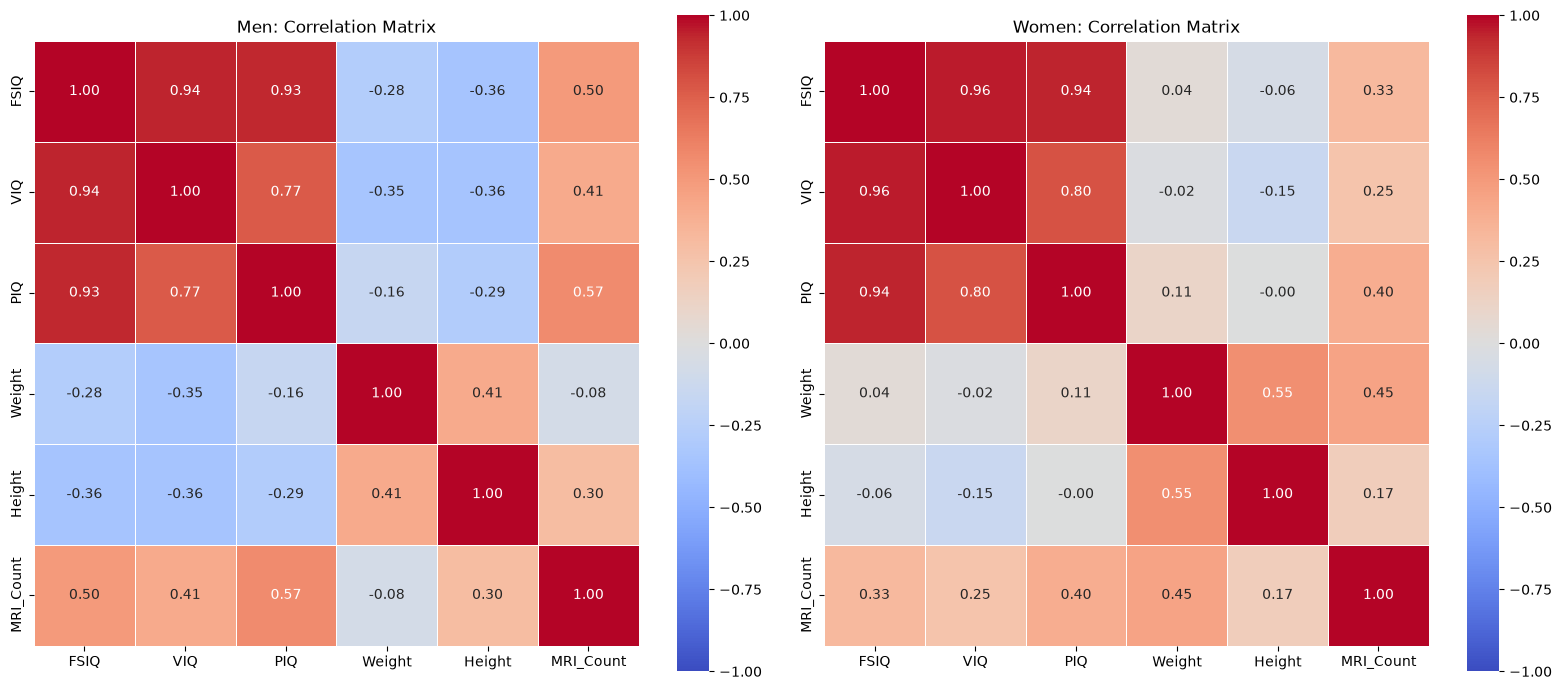

In [21]:
def plot_brain_heatmaps(men_df, women_df):

    features = ['FSIQ', 'VIQ', 'PIQ', 'Weight', 'Height', 'MRI_Count']

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    groups = [
        (men_df, 'Men'),
        (women_df, 'Women')
    ]

    for ax, (group_df, gender) in zip(axes, groups):

        correlation_matrix = group_df[features].corr(method='pearson')

        sns.heatmap(
            correlation_matrix,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            vmin=-1,
            vmax=1,
            center=0,
            square=True,
            linewidths=0.5,
            ax=ax
        )

        ax.set_title(f'{gender}: Correlation Matrix')

    plt.tight_layout()
    plt.show()

plot_brain_heatmaps(men_df, women_df)

Из полученной тепловой карты видим сильную корреляцию FSIQ и PIQ, FSIQ и VIQ. Это обусловено тем, что FSIQ высчитвается как композитный балл из результатов вербальынх и невербальных тестов. Также сильная корреляция PIQ и VIQ, это обосновывается тем, что любая когнитивная деятельность опирается на единый базовый ресурс. То есть, в основном, если человек показывает высокие результаты в словесных тестах, то с наибольшей вероятностью справится и с задачами на логику.

Есть умеренная корреляция между весом и ростом. Это неудивительно, так как более высокий человек весит больше.